# 🚀 Модуль 1. Урок 4. Визуализация в таблицах и ликвидация Chart Junk

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_01_excel/lesson_04_visualization_data_story.ipynb)

## 📌 Бизнес-контекст и методология
Эдвард Тафти ввел понятие **Chart Junk** — визуальный мусор, который отвлекает от сути данных.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import sqlite3
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    """Автоматически находит датасет локально или скачивает с GitHub репозитория курса."""
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    print(f"📥 Загрузка {filename} из репозитория курса...")
    urllib.request.urlretrieve(url, filename)
    print(f"✅ Датасет {filename} успешно готов!")
    return filename

db_path = ensure_dataset("ecommerce.db")
conn = sqlite3.connect(db_path)
print(f"🟢 Подключение к базе данных успешно установлено: {db_path}")


🟢 Подключение к базе данных успешно установлено: course\datasets\ecommerce.db


## 🔍 Разбор механики и демонстрация на реальных данных

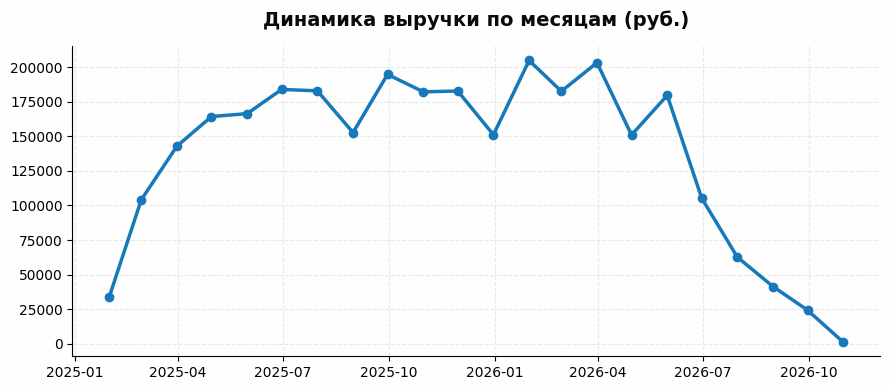

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

items_path = ensure_dataset("order_items.csv", subfolder="raw")
orders_path = ensure_dataset("orders.csv", subfolder="raw")

items = pd.read_csv(items_path)
orders = pd.read_csv(orders_path)
df = items.merge(orders, on="order_id")
df['order_date'] = pd.to_datetime(df['order_date'])

monthly_trend = df.set_index('order_date').resample('ME')['total_amount'].sum()

plt.figure(figsize=(9, 4), facecolor='#fefefe')
ax = plt.subplot(111)
ax.set_facecolor('#fefefe')
plt.plot(monthly_trend.index, monthly_trend.values, color='#1779ba', linewidth=2.5, marker='o')
plt.title("Динамика выручки по месяцам (руб.)", fontsize=14, fontweight='bold', pad=15, color='#0a0a0a')
plt.grid(True, linestyle='--', alpha=0.4, color='#cacaca')
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()


### 🎯 Практическое задание 1: Добавление расчетных меток MoM
Рассчитайте изменение выручки месяц к месяцу (MoM Growth %).

In [3]:
### ВАШ КОД ЗДЕСЬ
mom_growth = monthly_trend.pct_change() * 100
worst_month = mom_growth.idxmin()
worst_drop = mom_growth.min()

print(f"Наибольшая просадка зафиксирована в {worst_month.strftime('%Y-%m')}: {worst_drop:.1f}%")
assert not mom_growth.empty, "Ряд не должен быть пустым"
print("✅ Тест успешно пройден!")


Наибольшая просадка зафиксирована в 2026-10: -95.8%
✅ Тест успешно пройден!


### 💡 Чек-лист чистоты бизнес-графика
1. Заголовок содержит ключевой инсайт.
2. Числа отформатированы с разделителями тысяч.
3. Акцентный цвет выделяет только ключевые точки.